# Features y disponibilidad temporal

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.datos import cargar
from src.pipeline import preparar, dividir, FEATURES, TARGET, pliegues
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
obt, metadata = cargar()
datos = preparar(obt)
train, holdout = dividir(datos)
print({'fuente': metadata['tabla'], 'sha256': metadata['sha256'], 'filas_obt': len(obt), 'entrenamiento': len(train), 'holdout_reservado': len(holdout)})


{'fuente': 'PORTAFOLIO.OBT.OBT_ACCION_MES', 'sha256': 'f66dd033f81468360eb4eab3efb477bc8bdb3703d866837fb45461d2eb1b1240', 'filas_obt': 87178, 'entrenamiento': 46926, 'holdout_reservado': 11360}


Dos candidatas: vol_relativa = vol_21d / vol_63d identifica cambios de régimen; momentum_por_riesgo = momentum_12_1 / vol_63d responde a la dispersión de volatilidad observada en EDA. Se calculan al cierre del mes. Su aporte predictivo debe confirmarse por ablación en CV, no por correlación aislada.

,count,mean,std,min,25%,50%,75%,max
vol_relativa,46926.0,0.969962,0.238610,0.000000,0.804895,0.960254,1.122138,1.718211
momentum_por_riesgo,46926.0,0.506351,0.925091,-3.137523,-0.156936,0.451236,1.129639,4.923503
ret_log_mes_siguiente,46926.0,0.007563,0.082115,-1.223668,-0.034293,0.011856,0.053360,0.590356


,vol_relativa,momentum_por_riesgo,ret_log_mes_siguiente
vol_relativa,1.000000,0.057687,0.017891
momentum_por_riesgo,0.057687,1.000000,-0.031685
ret_log_mes_siguiente,0.017891,-0.031685,1.000000


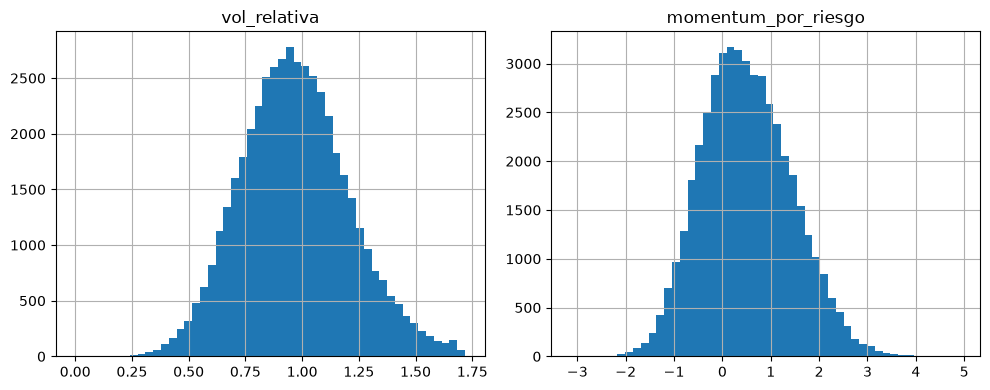

In [2]:
display(train[['vol_relativa','momentum_por_riesgo',TARGET]].describe().T); display(train[['vol_relativa','momentum_por_riesgo',TARGET]].corr(method='spearman')); train[['vol_relativa','momentum_por_riesgo']].hist(bins=50,figsize=(10,4)); plt.tight_layout(); plt.show()

In [3]:
assert not any('siguiente' in x for x in FEATURES)
assert 'sigue_en_sp500' not in FEATURES
for it,iv in pliegues(train):
    assert train.iloc[it].mes_objetivo.max() < pd.Period(str(train.iloc[iv].anio_mes.min()),freq='M')
print('Sin columnas de futuro en X y pliegues temporales con purga verificados.')

Sin columnas de futuro en X y pliegues temporales con purga verificados.


Limitación pendiente: los precios ajustados y la bolsa actual no son snapshots point-in-time. La interpolación de Silver usa un vecino posterior; el snapshot actual debe auditarse antes de declarar ausencia total de fuga. La validación de nombres y fechas anterior no prueba por sí sola la disponibilidad histórica de la fuente.